# Lab 2: Are Languages Represented in Disjoint Subspaces?



## Part 2 - Do languages share a subspace?

This notebook contains the source code for Part 2. 

In [1]:
# Import the required libraries, fix random seeds, and create a directory for cached representations.
from pathlib import Path
import random

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from transformers import AutoModelForMaskedLM, AutoTokenizer


# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {DEVICE}")

PyTorch version: 2.10.0
Device: cpu


In [2]:
# Load the pre-trained BERT model and tokenizer
MODEL_ID = "google-bert/bert-base-multilingual-cased"
REVISION = "3f076fdb1ab68d5b2880cb87a0886f315b8146f8"

tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
model = AutoModelForMaskedLM.from_pretrained(MODEL_ID, revision=REVISION).eval()
torch.set_grad_enabled(False)

print(f"Vocabulary size: {len(tok):,}")
print(f"Hidden size: {model.config.hidden_size}")
print(f"Encoder layers: {model.config.num_hidden_layers}")
#print(model.bert.encoder.layer[0]) # attention, intermediate, output

# Check that the tokenizer and model have the expected properties
assert len(tok) == 119_547
assert model.config.hidden_size == 768
assert model.config.num_hidden_layers == 12

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

BertForMaskedLM LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocabulary size: 119,547
Hidden size: 768
Encoder layers: 12


In [3]:
from huggingface_hub import login

login()

In [4]:
from huggingface_hub import whoami

# check the name of the logged-in user
print(whoami()["name"])

zuonawunawu


In [5]:
def load_flores(code, split):
    """One FLORES+ language variety as a DataFrame sorted by sentence id."""
    df = load_dataset(
        "openlanguagedata/flores_plus",
        code,
        split=split
    ).to_pandas()
    df["id"] = df["id"].astype(int)
    return df.sort_values("id").reset_index(drop=True)

# The six languages of Parts 2 and 3
LANGS = [
    "eng_Latn",
    "fra_Latn",
    "deu_Latn",
    "rus_Cyrl",
    "cmn_Hans",
    "yor_Latn",
]

# Load the dev split for the six languages
dev = {code: load_flores(code, "dev") for code in LANGS}

assert all(
    (d["id"] == dev["eng_Latn"]["id"]).all()
    for d in dev.values()
)

# Load the devtest split for the six languages
devtest = {code: load_flores(code, "devtest") for code in LANGS}

assert all(
    (d["id"] == devtest["eng_Latn"]["id"]).all()
    for d in devtest.values()
)

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

In [6]:
# Print the sizes of the dev and devtest splits for each language, as well as the columns of the English DataFrame.
print("dev sizes:", {code: len(df) for code, df in dev.items()})
print("devtest sizes:", {code: len(df) for code, df in devtest.items()})
print("Columns:", dev["eng_Latn"].columns.tolist())

dev sizes: {'eng_Latn': 997, 'fra_Latn': 997, 'deu_Latn': 997, 'rus_Cyrl': 997, 'cmn_Hans': 997, 'yor_Latn': 997}
devtest sizes: {'eng_Latn': 1012, 'fra_Latn': 1012, 'deu_Latn': 1012, 'rus_Cyrl': 1012, 'cmn_Hans': 1012, 'yor_Latn': 1012}
Columns: ['id', 'iso_639_3', 'iso_15924', 'glottocode', 'variant', 'text', 'url', 'domain', 'topic', 'has_image', 'has_hyperlink', 'last_updated', 'split']


In [7]:
# Display the first 3 rows of the English dev split
display(dev["eng_Latn"].head(3))

,id,iso_639_3,iso_15924,glottocode,variant,text,url,domain,topic,has_image,has_hyperlink,last_updated,split
0,0,eng,Latn,stan1293,,"On Monday, scientists from the Stanford Univer...",https://en.wikinews.org/wiki/Scientists_say_ne...,wikinews,health,yes,yes,1.0,dev
1,1,eng,Latn,stan1293,,Lead researchers say this may bring early dete...,https://en.wikinews.org/wiki/Scientists_say_ne...,wikinews,health,yes,yes,1.0,dev
2,2,eng,Latn,stan1293,,The JAS 39C Gripen crashed onto a runway at ar...,https://en.wikinews.org/wiki/Fighter_jet_crash...,wikinews,accident,yes,yes,1.0,dev


In [8]:
def encode(sentences, max_length=256):
    enc = tok(
        sentences,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
        return_special_tokens_mask=True
    )
    special = enc.pop("special_tokens_mask").bool()
    keep = enc["attention_mask"].bool() & ~special  # (B, T): real word pieces
    return enc, keep


def sentence_reps(sentences, batch_size=32):
    """Mean-pooled hidden states of all layers: array of shape (13, N, 768)."""
    chunks = []

    for i in range(0, len(sentences), batch_size):
        enc, keep = encode(sentences[i:i + batch_size])
        hs = model.bert(
            **enc,
            output_hidden_states=True
        ).hidden_states

        H = torch.stack(hs)                       # (13, B, T, 768)
        w = keep.unsqueeze(-1).float()            # (B, T, 1)
        chunks.append(
            (H * w).sum(2) / w.sum(1)             # (13, B, 768)
        )

    return torch.cat(chunks, dim=1).numpy()

In [9]:
# Test the sentence_reps function
TEXT_COLUMN = "text"

sample_sentences = dev["eng_Latn"][TEXT_COLUMN].iloc[:3].tolist()
sample_reps = sentence_reps(sample_sentences, batch_size=3)

print(f"Sample representation shape: {sample_reps.shape}")

Sample representation shape: (13, 3, 768)


### Task 2.1 - Extract and inspect the representations

#### Question 14

In [11]:
from pathlib import Path

# Compute and cache the representations of both splits for the six languages
cache_dir = Path("representations")
cache_dir.mkdir(exist_ok=True)

for code in LANGS:
    print(f"Encoding {code}")

    for split, data in [
        ("dev", dev),
        ("devtest", devtest),
    ]:
        reps = sentence_reps(data[code]["text"].tolist())
        np.save(cache_dir / f"{code}_{split}.npy", reps)

        print(split, reps.shape)

Encoding eng_Latn
dev (13, 997, 768)
devtest (13, 1012, 768)
Encoding fra_Latn
dev (13, 997, 768)
devtest (13, 1012, 768)
Encoding deu_Latn
dev (13, 997, 768)
devtest (13, 1012, 768)
Encoding rus_Cyrl
dev (13, 997, 768)
devtest (13, 1012, 768)
Encoding cmn_Hans
dev (13, 997, 768)
devtest (13, 1012, 768)
Encoding yor_Latn
dev (13, 997, 768)
devtest (13, 1012, 768)


Using the provided `sentence_reps` function, I computed the representations of the `dev` and `devtest` splits for all six languages. Each array was saved in the `representations/` directory as **`{language}_{split}.npy`**. The resulting shapes were \((13, 997, 768)\) for `dev` and \((13, 1012, 768)\) for `devtest`.

In [12]:
# Load the cached representations
dev_reps = {
    code: np.load(f"representations/{code}_dev.npy")
    for code in LANGS
}

devtest_reps = {
    code: np.load(f"representations/{code}_devtest.npy")
    for code in LANGS
}


#### Question 15

In [28]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

mean_norms = {}
mean_cosines = {}

for code in LANGS:
    reps = np.load(f"representations/{code}_dev.npy")

    # Average vector norm at each layer
    mean_norms[code] = np.linalg.norm(
        reps, axis=2
    ).mean(axis=1)

    # Average cosine similarity between 1,000 pairs
    cosines = []

    for X in reps:
        n = len(X)

        i = rng.integers(0, n, size=1000)
        j = rng.integers(0, n - 1, size=1000)
        j += j >= i

        cosine = (
            (X[i] * X[j]).sum(axis=1)
            / (
                np.linalg.norm(X[i], axis=1)
                * np.linalg.norm(X[j], axis=1)
            )
        )

        cosines.append(cosine.mean())

    mean_cosines[code] = np.array(cosines)

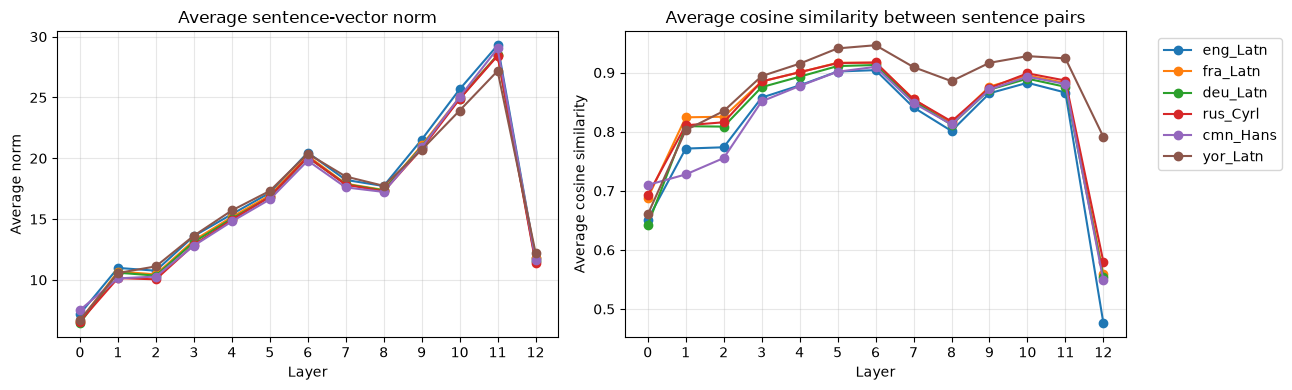

In [32]:
# Plot the average vector norms and cosine similarities for each language across layers
layers = range(13)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for code in LANGS:
    axes[0].plot(
        layers,
        mean_norms[code],
        marker="o",
        label=code
    )

    axes[1].plot(
        layers,
        mean_cosines[code],
        marker="o",
        label=code
    )

axes[0].set_xlabel("Layer")
axes[0].set_ylabel("Average norm")
axes[0].set_title("Average sentence-vector norm")

axes[1].set_xlabel("Layer")
axes[1].set_ylabel("Average cosine similarity")
axes[1].set_title("Average cosine similarity between sentence pairs")

for ax in axes:
    ax.set_xticks(range(13))
    ax.grid(alpha=0.3)

axes[1].legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

The six languages followed similar norm patterns: the average norm generally increased across the network, peaked at layer 11, and dropped sharply at layer 12. Mean cosine similarity was high in the middle layers, mostly between 0.8 and 0.95, before also decreasing at the final layer. Yoruba showed consistently higher cosine similarities than the other languages, particularly at layer 12.

#### Question 16

hidden_states[0] is the output of the embedding layer, before any Transformer layer is applied. It combines the WordPiece, position, and token-type embeddings. Even without contextual information, the tokens already provide strong clues about the language. Languages with distinct scripts use different parts of mBERT's shared vocabulary, so they can already be identified at this layer.

#### Question 17

[CLS] represents the sequence as a whole, while [SEP] marks its boundary. Since neither token corresponds to an actual word, including them could bias the mean-pooled representation, especially for shorter sentences. Averaging only the WordPiece tokens therefore gives a representation that better reflects the sentence content.

#### Question 18


FLORES+ is a parallel corpus, so sentences with the same ID express the same content in different languages. If all representations were combined and split randomly, one translation could be used for fitting while another translation of the same sentence appeared in the evaluation set. This would create data leakage and could make the results overly optimistic.

#### Question 19

As shown in Figure in Question 15, the average cosine similarities are very high in the middle layers, mostly between 0.8 and 0.95. 
This suggests that the sentence representations are strongly anisotropic: most vectors point in similar directions instead of being
evenly distributed across the space.
The decrease at layer 12 indicates that the representations become more dispersed in the final layer, although they are still not fully isotropic. Yoruba remains more concentrated than the other languages, as shown by its consistently higher cosine similarities.

### Task 2.2 - Look for rogue dimensions (optional)

#### Question 20

In [139]:
cc_by_layer = np.empty((13, 768))
dominant_dims = np.empty((13, 3), dtype=int)
top3_shares = np.empty(13)

# Compute CC_i on the pooled dev representations
for layer in range(13):
    pooled_reps = np.concatenate([
        dev_reps[code][layer]
        for code in LANGS
    ])

    unit_reps = pooled_reps / np.linalg.norm(
        pooled_reps, axis=1, keepdims=True
    )
    cc_by_layer[layer] = unit_reps.mean(axis=0) ** 2

    dominant_dims[layer] = np.argsort(
        cc_by_layer[layer]
    )[-3:][::-1]

    top3_shares[layer] = (
        cc_by_layer[layer, dominant_dims[layer]].sum()
        / cc_by_layer[layer].sum()
    )

    print(
        f"Layer {layer}:",
        f"dims={dominant_dims[layer].tolist()},",
        f"share={top3_shares[layer]:.2%}",
    )

Layer 0: dims=[423, 689, 157], share=32.42%
Layer 1: dims=[689, 195, 423], share=65.00%
Layer 2: dims=[195, 689, 731], share=67.54%
Layer 3: dims=[195, 731, 423], share=84.59%
Layer 4: dims=[195, 731, 423], share=87.77%
Layer 5: dims=[195, 731, 423], share=91.93%
Layer 6: dims=[195, 731, 227], share=89.90%
Layer 7: dims=[195, 227, 731], share=85.26%
Layer 8: dims=[227, 195, 731], share=79.35%
Layer 9: dims=[227, 195, 731], share=81.56%
Layer 10: dims=[227, 731, 423], share=85.78%
Layer 11: dims=[227, 731, 423], share=85.71%
Layer 12: dims=[423, 731, 371], share=12.30%


For each layer, I pooled the `dev` representations of the six languages and normalised every sentence vector. I computed $CC_i=\bar{u}_i^2$ for each dimension and selected the three largest terms. The dimension indices below use zero-based indexing.

The concentration was strongest in the middle layers. From layers 3 to 11, the three dominant dimensions accounted for 79.35-91.93% of the total, with the highest share at layer 5. Dimensions 195, 731, 423, and 227 appeared repeatedly, showing that a small set of rogue dimensions strongly influenced cosine similarity. The share dropped to 12.30% at layer 12, where the contribution was more widely distributed.

#### Question 21

In [140]:
language_cc = {
    code: np.empty((13, 768))
    for code in LANGS
}
language_dominant_dims = {
    code: np.empty((13, 3), dtype=int)
    for code in LANGS
}
language_top3_shares = {
    code: np.empty(13)
    for code in LANGS
}

# Compute CC_i separately for each language
for code in LANGS:
    for layer in range(13):
        language_reps = dev_reps[code][layer]
        language_unit_reps = language_reps / np.linalg.norm(
            language_reps, axis=1, keepdims=True
        )

        language_cc[code][layer] = (
            language_unit_reps.mean(axis=0) ** 2
        )
        language_dominant_dims[code][layer] = np.argsort(
            language_cc[code][layer]
        )[-3:][::-1]

        language_top3_shares[code][layer] = (
            language_cc[
                code
            ][layer, language_dominant_dims[code][layer]].sum()
            / language_cc[code][layer].sum()
        )

In [141]:
dominant_dimensions_table = pd.DataFrame({
    code: [
        f"{', '.join(map(str, language_dominant_dims[code][layer]))} "
        f"({language_top3_shares[code][layer]:.1%})"
        for layer in range(13)
    ]
    for code in LANGS
})

dominant_dimensions_table.index.name = "Layer"
display(dominant_dimensions_table)

,eng_Latn,fra_Latn,deu_Latn,rus_Cyrl,cmn_Hans,yor_Latn
Layer,,,,,,
0,"423, 689, 157 (20.6%)","423, 689, 157 (20.8%)","423, 689, 439 (21.5%)","423, 429, 207 (18.8%)","423, 429, 207 (16.4%)","423, 689, 157 (14.5%)"
1,"689, 195, 423 (59.5%)","689, 195, 731 (55.5%)","689, 195, 423 (54.4%)","689, 195, 423 (53.4%)","689, 195, 423 (44.8%)","689, 195, 423 (32.6%)"
2,"195, 689, 731 (61.6%)","195, 689, 731 (60.2%)","195, 689, 731 (58.3%)","195, 689, 731 (59.8%)","195, 689, 731 (55.2%)","195, 689, 731 (34.3%)"
3,"195, 731, 423 (80.8%)","195, 731, 423 (80.4%)","195, 731, 423 (79.5%)","195, 731, 423 (80.4%)","195, 731, 423 (79.0%)","195, 731, 423 (51.1%)"
4,"195, 731, 423 (85.2%)","195, 731, 423 (84.7%)","195, 731, 423 (84.0%)","195, 731, 423 (85.0%)","195, 731, 423 (83.3%)","195, 731, 423 (58.8%)"
5,"195, 731, 423 (90.2%)","195, 731, 423 (90.2%)","195, 731, 423 (90.0%)","195, 731, 423 (90.2%)","195, 731, 423 (88.9%)","195, 731, 423 (72.1%)"
6,"195, 731, 227 (89.0%)","195, 731, 227 (88.7%)","195, 731, 227 (88.3%)","195, 731, 423 (88.4%)","195, 731, 227 (87.6%)","195, 731, 423 (77.6%)"
7,"195, 227, 731 (84.1%)","195, 227, 731 (83.5%)","195, 227, 731 (83.6%)","195, 227, 731 (83.2%)","195, 227, 731 (83.1%)","195, 227, 731 (69.0%)"
8,"227, 195, 731 (78.7%)","227, 195, 731 (77.3%)","227, 195, 731 (78.0%)","227, 195, 731 (77.0%)","227, 195, 731 (77.3%)","195, 227, 731 (61.8%)"


I repeated the calculation separately for each language. The dominant dimensions were largely shared across languages. Layers 2-5, 7, and 9 had the same three dominant dimensions for all six languages. At layer 8, all languages also had the same set of dimensions, with a different ordering for Yoruba. Dimensions 195, 731, 423, and 227 appeared repeatedly across languages and layers.

Some differences occurred in the lower and final layers and in the third-ranked dimension of layers 6, 10, and 11. Yoruba generally had the same dominant dimensions as the other languages, but their combined share was lower. These results suggest that the main rogue dimensions are mostly shared across languages, although their strength varies.

#### Question 22

In [145]:
# Pool the six languages along the sentence dimension
pooled_dev_reps = np.concatenate(
    [dev_reps[code] for code in LANGS], axis=1
)

# One mean and standard deviation per layer and coordinate
standardisation_mean = pooled_dev_reps.mean(axis=1, keepdims=True)
standardisation_std = pooled_dev_reps.std(axis=1, keepdims=True)

# Apply the dev statistics to both splits
std_dev_reps = {
    code: (dev_reps[code] - standardisation_mean) / standardisation_std
    for code in LANGS
}

std_devtest_reps = {
    code: (devtest_reps[code] - standardisation_mean) / standardisation_std
    for code in LANGS
}

In [147]:
# Check that pooled dev has mean 0, standard deviation 1, and unchanged shapes
pooled_std_dev = np.concatenate(
    [std_dev_reps[code] for code in LANGS],
    axis=1,
)

print(
    "Maximum absolute mean:",
    np.abs(pooled_std_dev.mean(axis=1)).max(),
)
print(
    "Standard-deviation range:",
    pooled_std_dev.std(axis=1).min(),
    pooled_std_dev.std(axis=1).max(),
)
print(
    "Shapes:",
    std_dev_reps["eng_Latn"].shape,
    std_devtest_reps["eng_Latn"].shape,
)

Maximum absolute mean: 3.7448895e-05
Standard-deviation range: 0.9999969 1.0000031
Shapes: (13, 997, 768) (13, 1012, 768)


To verify the transformation, I pooled the standardised `dev` representations and checked their coordinate statistics. The maximum absolute mean was close to zero, and all standard deviations were close to one, confirming that the standardisation was applied correctly.

#### Question 23

Let $\mathbf{u}$ and $\mathbf{v}$ be the normalised representations of
two independently drawn sentences. Their cosine similarity is

$$
\cos(\mathbf{u},\mathbf{v})
= \mathbf{u}^{\top}\mathbf{v}
= \sum_i u_i v_i.
$$

Since the two sentences are drawn independently from the same distribution,

$$
\mathbb{E}[\cos(\mathbf{u},\mathbf{v})]
= \sum_i \mathbb{E}[u_i v_i]
= \sum_i \mathbb{E}[u_i]\mathbb{E}[v_i]
= \sum_i \mathbb{E}[u_i]^2.
$$

The sample mean $\bar{u}_i$ estimates $\mathbb{E}[u_i]$. Since
$CC_i=\bar{u}_i^2$, we obtain

$$
\sum_i CC_i
= \sum_i \bar{u}_i^2
\approx \mathbb{E}[\cos(\mathbf{u},\mathbf{v})].
$$

Therefore, the sum of the coordinate contributions estimates the
expected cosine similarity between two independently drawn sentences.

#### Question 24

As shown in the Q20 and Q21 tables, the dominant dimensions were largely shared across languages at the same layer. In many middle layers, all
six languages had exactly the same three dominant dimensions. Yoruba usually shared these dimensions as well, although their combined contribution was lower.

The dominant dimensions were only partly shared across layers. Dimension 689 was especially important in the lower layers, dimension 195 dominated many middle layers, and dimension 227 became prominent in the upper layers. Dimensions 423 and 731 appeared repeatedly across a wider range of layers. The rogue dimensions are therefore largely language-shared, but their importance changes through the model.

#### Question 25

For cosine-based retrieval, dominant dimensions shared across languages add a large common contribution to the similarity of many sentence pairs. This reduces the contrast between translations and unrelated sentences, so I expect standardisation to improve precision@1 by giving more weight to the remaining dimensions.

For subspace overlap, captured variance gives more importance to high-variance coordinates. If the same rogue dimensions dominate every
language, they can make the principal subspaces appear more similar and inflate $\omega_k$. I therefore expect standardisation to reduce the overlap scores if they were mainly driven by these dimensions.

#### Question 26

We use pooled statistics so that all six languages receive the same transformation. This reduces the effect of globally dominant dimensions while keeping the differences between languages.
If each language were standardised separately, its mean and variance differences would be removed, and each language would use a different scaling. This could make the languages look artificially similar and would make cross-lingual comparisons less reliable.

### Task 2.3 - Can the language be decoded?


#### Question 27

In [41]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create the language labels
y_dev = np.repeat(LANGS, 997)
y_devtest = np.repeat(LANGS, 1012)

raw_accuracies = []

# Train and evaluate one language classifier per layer
for layer in range(13):
    X_dev = np.concatenate([
        dev_reps[code][layer] for code in LANGS
    ])

    X_devtest = np.concatenate([
        devtest_reps[code][layer] for code in LANGS
    ])

    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )

    probe.fit(X_dev, y_dev)
    accuracy = probe.score(X_devtest, y_devtest)
    raw_accuracies.append(accuracy)

    print(f"Layer {layer}: {accuracy:.6f}")

Layer 0: 1.000000
Layer 1: 0.999835
Layer 2: 1.000000
Layer 3: 1.000000
Layer 4: 1.000000
Layer 5: 1.000000
Layer 6: 1.000000
Layer 7: 1.000000
Layer 8: 0.999835
Layer 9: 1.000000
Layer 10: 1.000000
Layer 11: 0.999835
Layer 12: 0.999835


At each layer, we combined the representations of the six languages and used their language codes as labels. We then trained a pipeline consisting of a `StandardScaler` and a logistic-regression classifier on `dev`, and evaluated it on `devtest`. Accuracy was at least 99.98% at every layer, with perfect accuracy at nine of the thirteen layers.

#### Question 28

In [42]:
centered_accuracies = []

# Centre each language using its dev mean
for layer in range(13):
    X_dev = []
    X_devtest = []

    for code in LANGS:
        mean = dev_reps[code][layer].mean(axis=0)

        X_dev.append(dev_reps[code][layer] - mean)
        X_devtest.append(devtest_reps[code][layer] - mean)

    X_dev = np.concatenate(X_dev)
    X_devtest = np.concatenate(X_devtest)

    # Train on centred dev and evaluate on centred devtest
    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )

    probe.fit(X_dev, y_dev)
    accuracy = probe.score(X_devtest, y_devtest)
    centered_accuracies.append(accuracy)

    print(f"Layer {layer}: {accuracy:.6f}")

Layer 0: 0.166667
Layer 1: 0.166667
Layer 2: 0.166667
Layer 3: 0.166667
Layer 4: 0.166667
Layer 5: 0.166667
Layer 6: 0.166667
Layer 7: 0.166667
Layer 8: 0.166667
Layer 9: 0.166667
Layer 10: 0.166667
Layer 11: 0.166667
Layer 12: 0.166667


For each language and layer, we estimated the mean representation on `dev` and subtracted it from both splits. The same classification pipeline as in Q27 was then trained on the centred `dev` representations and evaluated on `devtest`.

After centring, accuracy dropped to 16.67% at every layer, which is the chance level for six languages.

In [148]:
# Repeat Q27 and Q28 using the standardised representations
std_raw_accuracies = []
std_centered_accuracies = []

for layer in range(13):
    # Standardised representations
    std_X_dev = np.concatenate([
        std_dev_reps[code][layer]
        for code in LANGS
    ])
    std_X_devtest = np.concatenate([
        std_devtest_reps[code][layer]
        for code in LANGS
    ])

    std_raw_probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )
    std_raw_probe.fit(std_X_dev, y_dev)
    std_raw_accuracy = std_raw_probe.score(
        std_X_devtest, y_devtest
    )
    std_raw_accuracies.append(std_raw_accuracy)

    # Per-language centring after standardisation
    std_centered_dev = []
    std_centered_devtest = []

    for code in LANGS:
        std_language_mean = std_dev_reps[code][layer].mean(axis=0)

        std_centered_dev.append(
            std_dev_reps[code][layer] - std_language_mean
        )
        std_centered_devtest.append(
            std_devtest_reps[code][layer] - std_language_mean
        )

    std_centered_dev = np.concatenate(std_centered_dev)
    std_centered_devtest = np.concatenate(std_centered_devtest)

    std_centered_probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )
    std_centered_probe.fit(std_centered_dev, y_dev)
    std_centered_accuracy = std_centered_probe.score(
        std_centered_devtest, y_devtest
    )
    std_centered_accuracies.append(std_centered_accuracy)

    print(
        f"Layer {layer}:",
        f"standardised={std_raw_accuracy:.6f},",
        f"standardised+centred={std_centered_accuracy:.6f}",
    )

Layer 0: standardised=1.000000, standardised+centred=0.166667
Layer 1: standardised=0.999835, standardised+centred=0.166667
Layer 2: standardised=1.000000, standardised+centred=0.166667
Layer 3: standardised=1.000000, standardised+centred=0.166667
Layer 4: standardised=1.000000, standardised+centred=0.166667
Layer 5: standardised=1.000000, standardised+centred=0.166667
Layer 6: standardised=1.000000, standardised+centred=0.166667
Layer 7: standardised=1.000000, standardised+centred=0.166667
Layer 8: standardised=0.999835, standardised+centred=0.166667
Layer 9: standardised=1.000000, standardised+centred=0.166667
Layer 10: standardised=1.000000, standardised+centred=0.166667
Layer 11: standardised=0.999835, standardised+centred=0.166667
Layer 12: standardised=0.999835, standardised+centred=0.166667


In [149]:
print(
    "Raw difference:",
    np.max(np.abs(
        np.array(std_raw_accuracies)
        - np.array(raw_accuracies)
    )),
)
print(
    "Centred difference:",
    np.max(np.abs(
        np.array(std_centered_accuracies)
        - np.array(centered_accuracies)
    )),
)

Raw difference: 0.0
Centred difference: 0.0


*Standardised representations.*

I repeated Q27 and Q28 with the standardised representations, but the results did not change. Accuracy was still 99.98-100% before per-language centring and 16.67% after centring. This is expected because the pipeline already standardises each feature before training the classifier.

#### Question 29

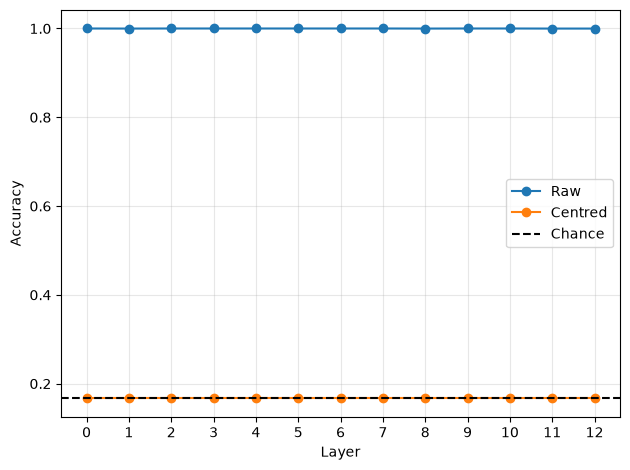

In [47]:
layers = range(13)

plt.plot(layers, raw_accuracies, marker="o", label="Raw")
plt.plot(layers, centered_accuracies, marker="o", label="Centred")
plt.axhline(1 / len(LANGS), linestyle="--", color="black", label="Chance")

plt.xlabel("Layer")
plt.ylabel("Accuracy")
plt.xticks(layers)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

As shown in Figure, accuracy was close to 100% at every layer with the raw representations. After per-language centring, it dropped to the chance level of 16.67% across all layers.

#### Question 30

The chance level is the expected accuracy of a classifier that has no useful information and guesses the class uniformly at random. Since the dataset contains six equally represented languages, the chance level is $1/6 \approx 16.67\%$, as shown in Figure of Question 29.

#### Question 31

The high accuracy does not prove that the languages occupy disjoint subspaces. A linear classifier can separate them using differences in their mean representations, even if their centred representations share the same subspace. For $L$ languages, these mean differences span at most $L-1$ dimensions, so five dimensions are sufficient for the six languages in this experiment. The drop to chance after centring suggests that the classifier mainly relied on these mean differences.

#### Question 32

Accuracy dropped from 99.98-100% to 16.67% after per-language centring, a decrease of about 83.3 percentage points. After centring, every language has a mean vector of zero, which removes the mean differences used by the linear classifier. With balanced classes, the classifier then has no consistent linear direction for separating the languages, which explains the chance-level accuracy. A result clearly above chance would show that the centred representations still contain linearly accessible language-specific structure beyond the mean offsets.

### Task 2.4 - Is language identity just an offset?

#### Question 33

For each English sentence, the correct translation is one of 1,012 candidates. A random retrieval therefore has a precision at 1 of $1/1012 \approx 0.000988$, or about 0.099%.

#### Question 34

In [52]:
# English is the query language; the other five are retrieval targets
TARGET_LANGS = [code for code in LANGS if code != "eng_Latn"]

def precision_at_1(english, target):
    # Normalise vectors so that their dot product is cosine similarity
    english = english / np.linalg.norm(english, axis=1, keepdims=True)
    target = target / np.linalg.norm(target, axis=1, keepdims=True)

    # Retrieve the most similar target sentence for each English sentence
    nearest = (english @ target.T).argmax(axis=1)

    # Parallel sentences have the same index in FLORES+
    return np.mean(nearest == np.arange(len(english)))


raw_p1 = {code: [] for code in TARGET_LANGS}
centered_p1 = {code: [] for code in TARGET_LANGS}

for layer in range(13):
    english = devtest_reps["eng_Latn"][layer]

    # Estimate the English mean on dev and apply it to devtest
    english_mean = dev_reps["eng_Latn"][layer].mean(axis=0)
    english_centered = english - english_mean

    for code in TARGET_LANGS:
        target = devtest_reps[code][layer]

        # Estimate each target-language mean on dev
        target_mean = dev_reps[code][layer].mean(axis=0)
        target_centered = target - target_mean

        raw_p1[code].append(
            precision_at_1(english, target)
        )
        centered_p1[code].append(
            precision_at_1(english_centered, target_centered)
        )

In [53]:
for code in TARGET_LANGS:
    print(code)
    print("Raw:     ", np.round(raw_p1[code], 3))
    print("Centred:", np.round(centered_p1[code], 3))

fra_Latn
Raw:      [0.434 0.519 0.77  0.892 0.955 0.981 0.992 0.995 0.993 0.992 0.982 0.97
 0.978]
Centred: [0.882 0.939 0.958 0.977 0.99  0.992 0.995 0.994 0.996 0.996 0.991 0.985
 0.975]
deu_Latn
Raw:      [0.275 0.408 0.634 0.813 0.941 0.978 0.991 0.996 0.994 0.989 0.984 0.968
 0.978]
Centred: [0.83  0.906 0.943 0.96  0.99  0.992 0.995 0.997 0.996 0.995 0.991 0.983
 0.987]
rus_Cyrl
Raw:      [0.068 0.257 0.538 0.688 0.838 0.931 0.962 0.98  0.989 0.973 0.974 0.952
 0.935]
Centred: [0.615 0.737 0.805 0.88  0.944 0.973 0.981 0.986 0.993 0.985 0.976 0.946
 0.944]
cmn_Hans
Raw:      [0.12  0.224 0.588 0.725 0.868 0.935 0.962 0.977 0.981 0.972 0.969 0.963
 0.95 ]
Centred: [0.758 0.836 0.869 0.929 0.963 0.977 0.988 0.989 0.987 0.986 0.977 0.968
 0.959]
yor_Latn
Raw:      [0.022 0.011 0.01  0.008 0.008 0.016 0.028 0.057 0.074 0.038 0.037 0.036
 0.087]
Centred: [0.153 0.148 0.17  0.202 0.21  0.255 0.275 0.273 0.298 0.28  0.228 0.213
 0.2  ]


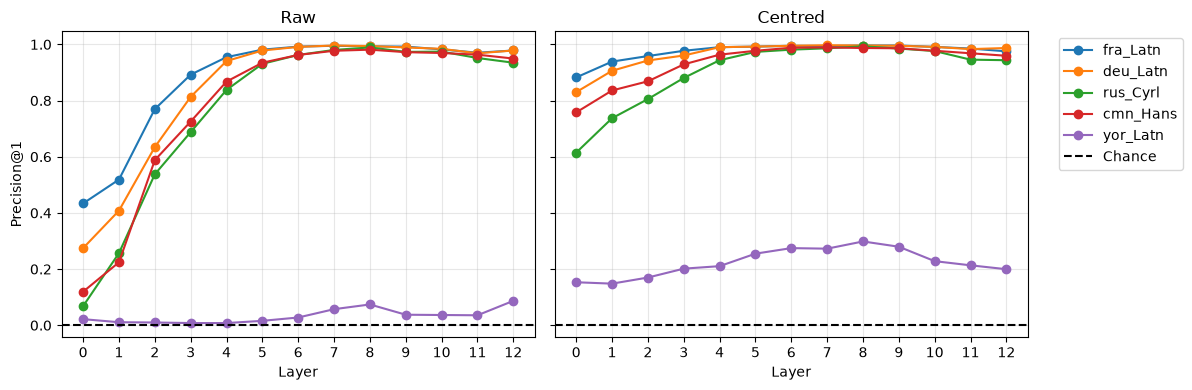

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for code in TARGET_LANGS:
    axes[0].plot(range(13), raw_p1[code], marker="o", label=code)
    axes[1].plot(range(13), centered_p1[code], marker="o", label=code)

for ax, title in zip(axes, ["Raw", "Centred"]):
    ax.axhline(1 / 1012, linestyle="--", color="black", label="Chance")
    ax.set_title(title)
    ax.set_xlabel("Layer")
    ax.set_xticks(range(13))
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Precision@1")
axes[1].legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

At each of the 13 layers, I used the 1,012 English `devtest` sentences as queries and the other five languages as retrieval targets. For each English sentence, I computed its cosine similarity with all 1,012 sentences in the target language and selected the nearest one. The retrieval was correct when the selected sentence had the same FLORES+ index as the English sentence. I calculated precision@1 for both the raw representations and the per-language-centred representations, using language means estimated only on `dev`.

As shown in the output and figure, centring improved retrieval for every target language, especially in the early layers. At layer 0, precision@1 for French, German, Russian, and Chinese increased from 0.068–0.434 to 0.615–0.882. The raw representations contain language-specific mean offsets, which place the language clouds at different affine positions and affect cosine similarity. Removing these offsets moves the clouds to a common origin and makes their shared linear structure easier to compare.

#### Question 35

As shown in Table and Figure of Question 34, the best retrieval results were generally found in layers 7 and 8. French and German performed best at layer 7 with the raw representations, while Russian and Chinese performed best at layer 8. After centring, the best results were also concentrated around layers 7–8. Raw Yoruba was an exception, with its highest score at layer 12.

This pattern is consistent with Pires et al. (2019), who found weaker retrieval in the lower layers and stronger results in the higher layers. It also agrees with Libovický et al. (2020), who reported layer 8 as the best-performing mBERT layer for sentence retrieval.

#### Question 36


Yoruba performed much worse than the other languages. Its best precision@1 increased from 0.087 to 0.298 after centring, but this was still far below the scores of around 0.99 achieved by the other languages. This suggests that mBERT aligns Yoruba and English less effectively, possibly because Yoruba had less training data during mBERT pre-training.

#### Question 37

In [153]:
# Repeat retrieval after standardisation and per-language centring
std_centered_p1 = {
    code: []
    for code in TARGET_LANGS
}

for layer in range(13):
    std_english = std_devtest_reps["eng_Latn"][layer]
    std_english_mean = std_dev_reps[
        "eng_Latn"
    ][layer].mean(axis=0)
    std_english_centered = std_english - std_english_mean

    for code in TARGET_LANGS:
        std_target = std_devtest_reps[code][layer]
        std_target_mean = std_dev_reps[
            code
        ][layer].mean(axis=0)
        std_target_centered = std_target - std_target_mean

        std_centered_p1[code].append(
            precision_at_1(
                std_english_centered,
                std_target_centered,
            )
        )

In [154]:
for code in TARGET_LANGS:
    print(code)
    print(
        "Centred:              ",
        np.round(centered_p1[code], 3),
    )
    print(
        "Standardised+centred: ",
        np.round(std_centered_p1[code], 3),
    )

fra_Latn
Centred:               [0.882 0.939 0.958 0.977 0.99  0.992 0.995 0.994 0.996 0.996 0.991 0.985
 0.975]
Standardised+centred:  [0.883 0.947 0.957 0.976 0.989 0.993 0.995 0.994 0.996 0.995 0.992 0.987
 0.979]
deu_Latn
Centred:               [0.83  0.906 0.943 0.96  0.99  0.992 0.995 0.997 0.996 0.995 0.991 0.983
 0.987]
Standardised+centred:  [0.83  0.915 0.94  0.962 0.992 0.992 0.995 0.998 0.996 0.994 0.993 0.987
 0.988]
rus_Cyrl
Centred:               [0.615 0.737 0.805 0.88  0.944 0.973 0.981 0.986 0.993 0.985 0.976 0.946
 0.944]
Standardised+centred:  [0.602 0.751 0.793 0.885 0.94  0.973 0.981 0.985 0.994 0.983 0.977 0.96
 0.942]
cmn_Hans
Centred:               [0.758 0.836 0.869 0.929 0.963 0.977 0.988 0.989 0.987 0.986 0.977 0.968
 0.959]
Standardised+centred:  [0.741 0.843 0.871 0.925 0.963 0.981 0.989 0.99  0.989 0.986 0.98  0.975
 0.96 ]
yor_Latn
Centred:               [0.153 0.148 0.17  0.202 0.21  0.255 0.275 0.273 0.298 0.28  0.228 0.213
 0.2  ]
Standardised+centred

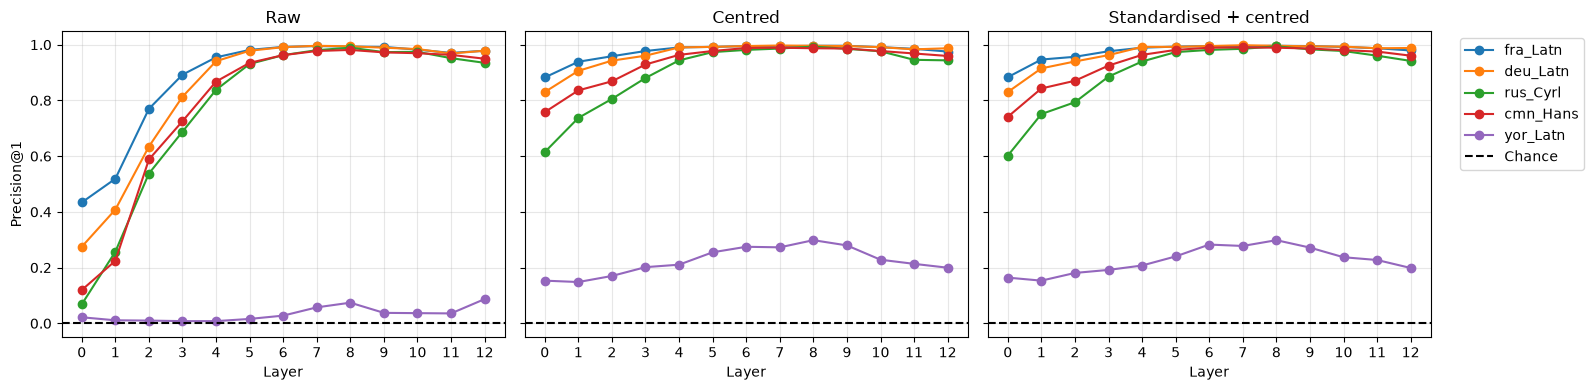

In [155]:
conditions = [
    ("Raw", raw_p1),
    ("Centred", centered_p1),
    ("Standardised + centred", std_centered_p1),
]

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4), sharey=True
)

for ax, (title, scores) in zip(axes, conditions):
    for code in TARGET_LANGS:
        ax.plot(
            range(13),
            scores[code],
            marker="o",
            label=code,
        )

    ax.axhline(
        1 / 1012,
        linestyle="--",
        color="black",
        label="Chance",
    )
    ax.set_title(title)
    ax.set_xlabel("Layer")
    ax.set_xticks(range(13))
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Precision@1")
axes[-1].legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

As shown in the figure, standardisation produced only small and mixed changes, all below about 0.02. The best results were still found around layers 7--8, and Yoruba remained much lower than the other languages.

The retrieval prediction from Q25 was therefore not clearly supported: standardisation did not consistently improve precision@1. This suggests that, after per-language centring, the shared rogue dimensions had little effect on the nearest-neighbour ranking.

### Task 2.5 - Measure the overlap between principal subspaces

#### Question 38

In [56]:
def principal_subspace(X, k):
    """Return the top-k principal directions of X."""
    Xc = X - X.mean(axis=0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Vt[:k].T


def random_subspace(d, k):
    """Return a random k-dimensional orthonormal basis."""
    Q, _ = np.linalg.qr(np.random.randn(d, k))
    return Q


def captured_variance(X, U):
    """Compute the fraction of variance captured by U."""
    Xc = X - X.mean(axis=0)
    return np.linalg.norm(Xc @ U, "fro") ** 2 / np.linalg.norm(Xc, "fro") ** 2


def overlap(X_B, U_A, U_B, U_rand):
    """Compute the normalised overlap from language A to language B."""
    c_A = captured_variance(X_B, U_A)
    c_B = captured_variance(X_B, U_B)
    c_rand = captured_variance(X_B, U_rand)

    return (c_A - c_rand) / (c_B - c_rand)

I centred the `dev` representations and used the first $k$ right singular vectors from SVD as the principal subspace. The random subspace was created by applying QR decomposition to a Gaussian matrix. The function $c(X,U)$ measures how much of the centred variance is captured by $U$. I then calculated $\omega_k(A \to B)$ by comparing language $A$'s subspace with a random subspace and language $B$'s own subspace.

#### Question 39

In [103]:
KS = [10, 50, 100]
d = dev_reps["eng_Latn"].shape[-1]

# Estimate the top 100 principal directions from dev
subspaces = {code: [] for code in LANGS}

for layer in range(13):
    for code in LANGS:
        subspaces[code].append(
            principal_subspace(dev_reps[code][layer], max(KS))
        )

# Keep the random baselines reproducible
np.random.seed(SEED)

# Compute overlap for every ordered language pair
omegas = {
    k: np.full((13, len(LANGS), len(LANGS)), np.nan)
    for k in KS
}

for k in KS:
    for layer in range(13):
        U_rand = random_subspace(d, k)

        for i, code_A in enumerate(LANGS):
            for j, code_B in enumerate(LANGS):
                if code_A == code_B:
                    continue

                omegas[k][layer, i, j] = overlap(
                    devtest_reps[code_B][layer],
                    subspaces[code_A][layer][:, :k],
                    subspaces[code_B][layer][:, :k],
                    U_rand,
                )

For each language and layer, I estimated the first 100 principal directions from the `dev` representations. I then selected the first 10, 50, or 100 directions for each value of \(k\). For every ordered pair of different languages \(A\rightarrow B\), I evaluated the overlap on language \(B\)'s `devtest` representations. This produced 30 ordered language pairs at each layer and for each value of \(k\). 

Both raw and standardised representations were analysed. The raw overlap results are reported here, and the effect of standardisation is examined in Q46.

In [104]:
# Check the shape and number of valid overlap scores for each k
for k in KS:
    print(
        f"k={k}",
        "shape:", omegas[k].shape,
        "values:", np.isfinite(omegas[k]).sum(),
    )

k=10 shape: (13, 6, 6) values: 390
k=50 shape: (13, 6, 6) values: 390
k=100 shape: (13, 6, 6) values: 390


To check the calculation, I examined the shape and number of finite values in each result array. Each array had shape `(13, 6, 6)`, representing the layers, source languages, and target languages. It contained 390 finite overlap scores, as expected from 13 layers and $6 \times 5$ ordered language pairs: $13 \times 6 \times 5 = 390$.

In [121]:
# Display the overlap matrix for k=50 at layer 8
pd.DataFrame(
    omegas[50][8],
    index=LANGS,
    columns=LANGS,
).round(3)

,eng_Latn,fra_Latn,deu_Latn,rus_Cyrl,cmn_Hans,yor_Latn
eng_Latn,NaN,0.916,0.914,0.890,0.840,0.353
fra_Latn,0.923,NaN,0.919,0.912,0.829,0.393
deu_Latn,0.911,0.911,NaN,0.919,0.830,0.383
rus_Cyrl,0.893,0.907,0.922,NaN,0.849,0.399
cmn_Hans,0.858,0.837,0.843,0.857,NaN,0.369
yor_Latn,0.465,0.488,0.485,0.491,0.460,NaN


As an example, I displayed the $6\times6$ overlap matrix for $k=50$ at layer 8. The same code can be used to inspect other values of $k$ and other layers.

#### Question 40

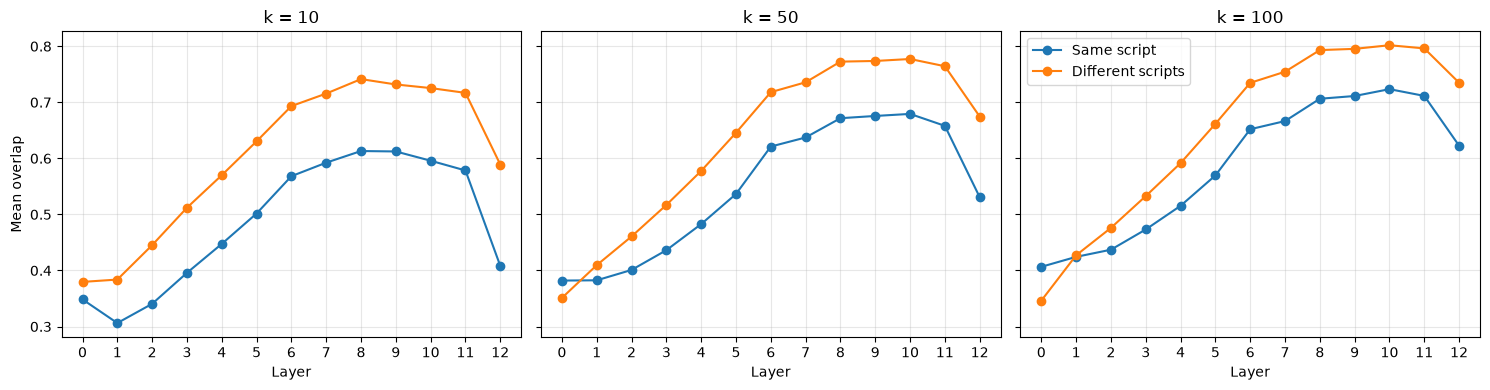

In [122]:
scripts = [code.split("_")[1] for code in LANGS]

# Separate language pairs by script
same_script = np.equal.outer(scripts, scripts)
np.fill_diagonal(same_script, False)
different_script = ~np.equal.outer(scripts, scripts)

# Plot the mean overlap across layers
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, k in zip(axes, KS):
    same_mean = [
        np.nanmean(omegas[k][layer][same_script])
        for layer in range(13)
    ]
    different_mean = [
        np.nanmean(omegas[k][layer][different_script])
        for layer in range(13)
    ]

    ax.plot(range(13), same_mean, marker="o", label="Same script")
    ax.plot(range(13), different_mean, marker="o", label="Different scripts")
    ax.set_title(f"k = {k}")
    ax.set_xlabel("Layer")
    ax.set_xticks(range(13))
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Mean overlap")
axes[-1].legend()
plt.tight_layout()
plt.show()

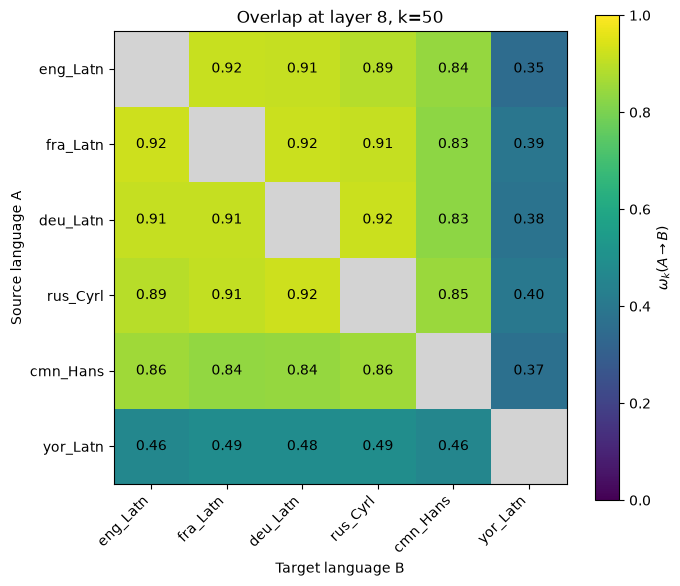

In [123]:
selected_k = 50
selected_layer = 8
matrix = omegas[selected_k][selected_layer]

# Plot the full overlap matrix for k=50 at layer 8
cmap = plt.cm.viridis.copy()
cmap.set_bad("lightgray")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=1)

ax.set_xticks(range(len(LANGS)), labels=LANGS, rotation=45, ha="right")
ax.set_yticks(range(len(LANGS)), labels=LANGS)
ax.set_xlabel("Target language B")
ax.set_ylabel("Source language A")
ax.set_title(f"Overlap at layer {selected_layer}, k={selected_k}")

for i in range(len(LANGS)):
    for j in range(len(LANGS)):
        if np.isfinite(matrix[i, j]):
            ax.text(
                j, i, f"{matrix[i, j]:.2f}",
                ha="center", va="center",
            )

plt.colorbar(im, ax=ax, label=r"$\omega_k(A\rightarrow B)$")
plt.tight_layout()
plt.show()

In [125]:
# supplentary analysis: exclude Yoruba from the overlap analysis
non_yoruba = np.array([code != "yor_Latn" for code in LANGS])
keep_pairs = np.outer(non_yoruba, non_yoruba)

for k in KS:
    same_without_yoruba = same_script & keep_pairs
    different_without_yoruba = different_script & keep_pairs

    print(
        f"k={k}, layer 8:",
        "same =", np.nanmean(omegas[k][8][same_without_yoruba]),
        "different =", np.nanmean(omegas[k][8][different_without_yoruba]),
    )

k=10, layer 8: same = 0.8993810952526983 different = 0.8597664793073637
k=50, layer 8: same = 0.9156748129979393 different = 0.870484973853798
k=100, layer 8: same = 0.9217606216388795 different = 0.8796828035420358


I grouped the ordered language pairs according to whether they used the same script and calculated the mean overlap at each layer. I plotted the results separately for $k=10$, $k=50$, and $k=100$. I also plotted the full $6 \times 6$ overlap matrix for $k=50$ at layer 8.

For all three values of $k$, the mean overlap generally increased across the lower and middle layers, reached its highest values around layers 8–10, and decreased at layer 12. Different-script pairs had higher mean overlap in most layers. However, the heatmap shows that most pairs not involving Yoruba had high overlap at layer 8, mostly between 0.83 and 0.92, while pairs involving Yoruba were much lower, between 0.35 and 0.49. Since Yoruba uses the Latin script, these pairs lowered the mean of the same-script group.

#### Question 41

In [135]:
X = devtest_reps["eng_Latn"][8]
n_random = 100

# Compare empirical captured variance with k/d
np.random.seed(SEED)

for k in KS:
    values = [
        captured_variance(X, random_subspace(d, k))
        for _ in range(n_random)
    ]
    print(f"k={k}: empirical={np.mean(values):.6f}, expected={k / d:.6f}")

k=10: empirical=0.013061, expected=0.013021
k=50: empirical=0.065103, expected=0.065104
k=100: empirical=0.130395, expected=0.130208


I verified this using the English `devtest` representations at layer 8 and 100 random subspaces for each value of $k$. As shown in the output, the empirical values were very close to the expected values $k/768$, confirming the theoretical result.

#### Question 42

The subspace $U_B$ is estimated on `dev` and evaluated on `devtest` to measure how well it generalises to unseen sentences. If the same sentences were used for both fitting and evaluation, the subspace would be optimised for that particular sample and could also capture sample-specific noise. This would overestimate $c(X_B^{\mathrm{test}}, U_B)$, which is used as the upper reference in the denominator, and could make $\omega_k(A\rightarrow B)$ artificially low.

#### Question 43

As shown in Figure of question 40, the overlap generally increased with $k$, especially in the middle layers. Larger subspaces include more directions that can be shared across languages.

As $k$ approaches $d=768$, the source, target, and random subspaces all approach the full representation space, so their captured variance approaches one. At $k=d$, $c(X,U_A)=c(X,U_B)=c(X,U_{\mathrm{rand}})=1$ and $\omega_k=(1-1)/(1-1)=0/0$, which is undefined.

The value of $k$ must remain much smaller than the number of sentences used to estimate the subspace. If $k$ is too large, the later principal directions may capture sample-specific noise and generalise poorly to `devtest`. Keeping $k$ small gives a more stable estimate of the principal subspace.

#### Question 44

The overlap is not symmetric because $\omega_k(A\rightarrow B)$ is evaluated on language $B$ and normalised using $B$'s own principal
subspace as the upper bound. Reversing the direction changes both the evaluation data and the upper bound.

As shown in Figure of Question 40, at layer 8 with $k=50$, the English-to-Yoruba overlap was 0.35, while the Yoruba-to-English overlap was 0.46.  Relative to each target language's own upper bound, the Yoruba subspace captured English variation more effectively than the English subspace captured Yoruba variation. This difference may be related to Yoruba's lower representation in mBERT pre-training, which can lead to less stable cross-lingual alignment.

#### Question 45

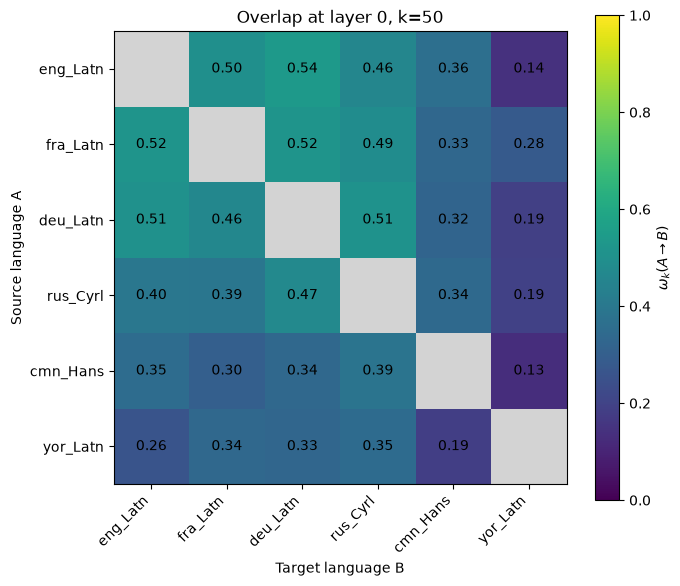

In [114]:
# Plot the full overlap matrix for k=50 at layer 0
selected_k = 50
selected_layer = 0
matrix = omegas[selected_k][selected_layer]

cmap = plt.cm.viridis.copy()
cmap.set_bad("lightgray")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=1)

ax.set_xticks(range(len(LANGS)), labels=LANGS, rotation=45, ha="right")
ax.set_yticks(range(len(LANGS)), labels=LANGS)
ax.set_xlabel("Target language B")
ax.set_ylabel("Source language A")
ax.set_title(f"Overlap at layer {selected_layer}, k={selected_k}")

# Show the overlap score in each cell
for i in range(len(LANGS)):
    for j in range(len(LANGS)):
        if np.isfinite(matrix[i, j]):
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center")

plt.colorbar(im, ax=ax, label=r"$\omega_k(A\rightarrow B)$")
plt.tight_layout()
plt.show()

As shown in Figure of Question 40, the lowest overlap generally occurred in layers 0–1. The overlap also decreased at layer 12, but it usually remained above the values in the lowest layers. At layer 0, different-script pairs had lower mean overlap for $k=50$ and $k=100$, although this pattern was not present for $k=10$.

This shows that the overlap at layer 0 varied considerably across language pairs. However, the lower overlap between different scripts does not provide sufficient evidence for $H_{\mathrm{disjoint}}$. Layer 0 contains the input embeddings before contextual processing, so languages with different scripts tend to use different WordPiece tokens. The lower overlap can therefore reflect script and tokenisation differences. Moreover, the mean overlap remained above zero and increased strongly in the later layers. $H_{\mathrm{disjoint}}$ predicts that one language's principal subspace should capture no more variance in another language than a random subspace, giving $\omega_k\approx0$.

#### Question 46

In [156]:
# Repeat Q39 using the standardised representations
std_subspaces = {
    code: []
    for code in LANGS
}

# Estimate the top 100 standardised principal directions from dev
for layer in range(13):
    for code in LANGS:
        std_subspaces[code].append(
            principal_subspace(
                std_dev_reps[code][layer],
                max(KS),
            )
        )

# Use the same random seed as in the original calculation
np.random.seed(SEED)

std_omegas = {
    k: np.full(
        (13, len(LANGS), len(LANGS)),
        np.nan,
    )
    for k in KS
}

# Compute standardised overlap for every ordered language pair
for k in KS:
    for layer in range(13):
        std_random_basis = random_subspace(d, k)

        for i, code_A in enumerate(LANGS):
            for j, code_B in enumerate(LANGS):
                if code_A == code_B:
                    continue

                std_omegas[k][layer, i, j] = overlap(
                    std_devtest_reps[code_B][layer],
                    std_subspaces[code_A][layer][:, :k],
                    std_subspaces[code_B][layer][:, :k],
                    std_random_basis,
                )

In [157]:
# Check the standardised overlap results
for k in KS:
    print(
        f"k={k}",
        "shape:", std_omegas[k].shape,
        "values:", np.isfinite(std_omegas[k]).sum(),
    )

k=10 shape: (13, 6, 6) values: 390
k=50 shape: (13, 6, 6) values: 390
k=100 shape: (13, 6, 6) values: 390


k=10: raw=0.556, standardised=0.539, change=-0.017
k=50: raw=0.596, standardised=0.588, change=-0.008
k=100: raw=0.624, standardised=0.621, change=-0.003


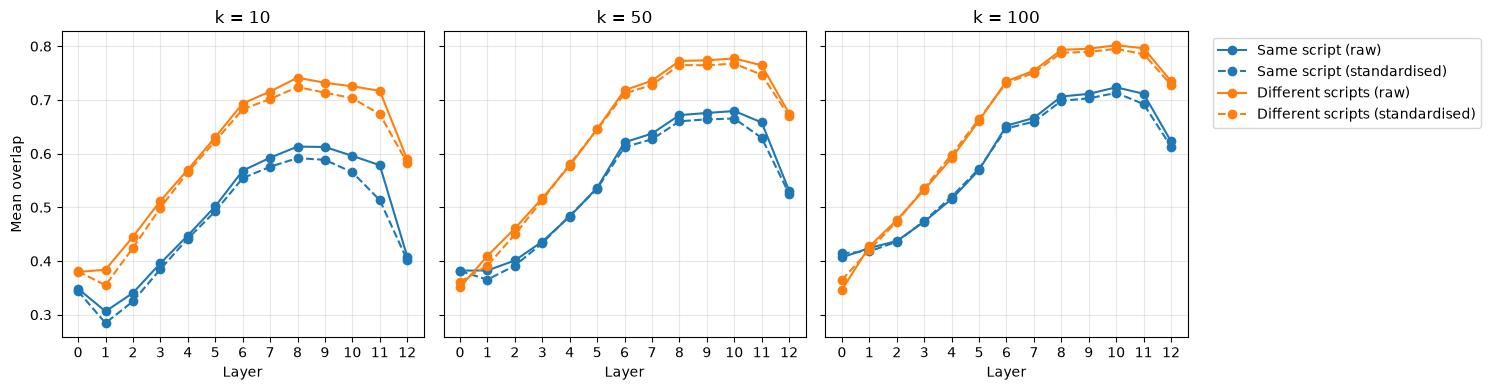

In [158]:
# Compare raw and standardised overlap
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

groups = [
    ("Same script", same_script, "tab:blue"),
    ("Different scripts", different_script, "tab:orange"),
]

for ax, k in zip(axes, KS):
    for label, mask, color in groups:
        raw_mean = np.nanmean(omegas[k][:, mask], axis=1)
        std_mean = np.nanmean(std_omegas[k][:, mask], axis=1)

        ax.plot(
            range(13), raw_mean,
            marker="o", color=color,
            label=f"{label} (raw)",
        )
        ax.plot(
            range(13), std_mean,
            marker="o", linestyle="--", color=color,
            label=f"{label} (standardised)",
        )

    ax.set(
        title=f"k = {k}",
        xlabel="Layer",
        xticks=range(13),
    )
    ax.grid(alpha=0.3)

    print(
        f"k={k}:",
        f"raw={np.nanmean(omegas[k]):.3f},",
        f"standardised={np.nanmean(std_omegas[k]):.3f},",
        f"change={np.nanmean(std_omegas[k] - omegas[k]):+.3f}",
    )

axes[0].set_ylabel("Mean overlap")
axes[-1].legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

I recomputed the principal subspaces and overlap scores using the standardised representations. As shown in the figure, standardisation slightly reduced the overall mean overlap from 0.556 to 0.539 for $k=10$, from 0.596 to 0.588 for $k=50$, and from 0.624 to 0.621 for $k=100$. However, the curves remained very similar. Overlap still increased through the middle layers, peaked around layers 8--10, and decreased at layer 12. The difference between the script groups also remained.

The overlap prediction from Q25 was therefore supported in direction, but the effect was small. Shared rogue dimensions slightly increased the overlap scores, but they did not explain the main pattern.

#### Question 47

No. A value of $\omega_k\approx1$ only shows that one language's principal subspace captures the variance of another language almost as well as the target language's own subspace. It does not show that the directions represent the same features across languages.

Under the superposition hypothesis, language-specific features can share the same dimensions because languages are nearly mutually exclusive. Superposed language-specific features can therefore produce highly overlapping principal subspaces. A high value of $\omega_k$ does not prove that the features themselves are shared across languages. A cross-lingual transfer test is needed to determine whether the same directions encode the same information.

### Task 2.6 — Same direction, same meaning?

#### Question 48

In [136]:
DOMAIN_LAYERS = [0, 8, 12]
SOURCE_LANG = "eng_Latn"

y_dev_domain = dev[SOURCE_LANG]["domain"]
y_devtest_domain = devtest[SOURCE_LANG]["domain"]

# Majority-class baseline on devtest
majority_baseline = y_devtest_domain.value_counts(normalize=True).max()

domain_scores = {}

for layer in DOMAIN_LAYERS:
    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000),
    )

    # Train the domain probe on English dev
    probe.fit(dev_reps[SOURCE_LANG][layer], y_dev_domain)

    # Evaluate within English and transfer to the other languages
    domain_scores[layer] = {
        code: probe.score(devtest_reps[code][layer], y_devtest_domain)
        for code in LANGS
    }

domain_scores = pd.DataFrame.from_dict(domain_scores, orient="index")
domain_scores.index.name = "Layer"

print(f"Majority baseline: {majority_baseline:.3f}")
display(domain_scores.round(3))

Majority baseline: 0.347


,eng_Latn,fra_Latn,deu_Latn,rus_Cyrl,cmn_Hans,yor_Latn
Layer,,,,,,
0,0.691,0.460,0.516,0.510,0.475,0.355
8,0.772,0.738,0.689,0.674,0.700,0.391
12,0.743,0.687,0.621,0.593,0.693,0.417



I trained a domain classifier on the English `dev` representations at layers 0, 8, and 12. I evaluated it on English `devtest` for within-language accuracy and on the other five languages for cross-lingual transfer. The majority-class baseline was 0.347.

The English within-language accuracy was above the baseline at all three layers. Transfer accuracy was also above the baseline for every language. Layer 8 gave the strongest results for French, German, Russian, and Chinese, while Yoruba performed best at layer 12. Yoruba had the lowest transfer accuracy overall.

#### Question 49

In [138]:
# Dev mean for each language and layer
dev_means = {
    code: dev_reps[code].mean(axis=1)
    for code in LANGS
}

centered_domain_scores = {}

for layer in DOMAIN_LAYERS:
    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000),
    )

    # Train on centred English dev
    X_train = (
        dev_reps[SOURCE_LANG][layer]
        - dev_means[SOURCE_LANG][layer]
    )
    probe.fit(X_train, y_dev_domain)

    # Evaluate on centred devtest representations
    centered_domain_scores[layer] = {
        code: probe.score(
            devtest_reps[code][layer] - dev_means[code][layer],
            y_devtest_domain,
        )
        for code in LANGS
    }

centered_domain_scores = pd.DataFrame.from_dict(
    centered_domain_scores,
    orient="index",
)
centered_domain_scores.index.name = "Layer"

display(centered_domain_scores.round(3))

,eng_Latn,fra_Latn,deu_Latn,rus_Cyrl,cmn_Hans,yor_Latn
Layer,,,,,,
0,0.691,0.564,0.551,0.516,0.547,0.383
8,0.772,0.746,0.723,0.715,0.701,0.450
12,0.743,0.690,0.662,0.667,0.686,0.427


For each selected layer, I estimated the mean representation of each language on `dev` and subtracted it from both its `dev` and `devtest`
representations. I then repeated the English-trained domain classification experiment from Q48. The results are shown in the table below.

The table shows that centring improved transfer accuracy for almost all languages and layers. Layer 8 gave the best transfer results for all five target languages, including an increase for Yoruba from 0.391 to 0.450. English accuracy remained unchanged because the `StandardScaler` already centred the English training distribution. Overall, the improvement suggests that language-specific mean offsets interfered with cross-lingual transfer.

#### Question 50

The FLORES+ sentences are translations of the same English source sentences. Translations with the same sentence ID express the same content and come from the same source article. The domain label of the English article is therefore also valid for all of its translations. This allows the same labels to be used when evaluating cross-lingual transfer.

#### Question 51

Language pairs with different scripts are more informative because they share fewer WordPiece tokens and surface forms. For languages using the same script, the probe may rely on shared names, numbers, punctuation, or similar spellings that are correlated with the domain. Successful transfer across different scripts provides stronger evidence that the model encodes domain information in shared internal directions.

#### Question 52

Centring removes the language-specific mean offset from each representation space. Without centring, a probe trained on English may be affected by the different position of the target-language point cloud, even if both languages encode domain information in similar directions. Centring places each language around the same origin, so the probe can focus on within-language variation related to the domain.

As shown in the Q48 and Q49 tables, centring improved transfer accuracy for almost all languages and layers. This suggests that language-specific mean offsets interfered with cross-lingual transfer.

#### Question 53

I compared the overlap scores from Q39 at layer 8 with $k=50$ with the centred domain-transfer results from Q49. The English within-language accuracy was 0.772, and the majority-class baseline was 0.347.

| | Transfer $\approx$ within-language | Transfer $\approx$ baseline |
|---|---|---|
| **High overlap $\omega$** | Eng → Fra ($\omega_{50}=0.92$, acc. = 0.746)<br>Eng → Deu ($\omega_{50}=0.91$, acc. = 0.723)<br>Eng → Rus ($\omega_{50}=0.89$, acc. = 0.715)<br>Eng → Cmn ($\omega_{50}=0.84$, acc. = 0.701) | None observed |
| **Low overlap $\omega$** | None observed | Eng → Yor ($\omega_{50}=0.35$, acc. = 0.450) |

**Table: Language pairs classified by overlap and centred transfer accuracy at layer 8.**


As shown in the table, English-French, English-German, English-Russian, and English-Chinese had high overlap and transfer accuracy close to the within-language result. These pairs therefore support the shared-features scenario.

English-Yoruba had the lowest overlap, and its transfer accuracy was closer to the baseline. It was therefore closest to the disjoint-subspaces scenario, although both values remained above the expected minimum. Overall, the results mainly support shared features, with weaker alignment between English and Yoruba. No pair clearly supported the superposed language-specific features scenario.

#### Additional Check with Standardised Representations

In [160]:
# Repeat Q48 and Q49 with the standardised representations
std_domain_scores = {}
std_centered_domain_scores = {}

for layer in DOMAIN_LAYERS:
    std_domain_scores[layer] = {}
    std_centered_domain_scores[layer] = {}

    # Standardised representations
    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )
    probe.fit(std_dev_reps[SOURCE_LANG][layer], y_dev_domain)

    for code in LANGS:
        std_domain_scores[layer][code] = probe.score(
            std_devtest_reps[code][layer],
            y_devtest_domain
        )

    # Standardised and per-language-centred representations
    means = {
        code: std_dev_reps[code][layer].mean(axis=0)
        for code in LANGS
    }

    probe.fit(
        std_dev_reps[SOURCE_LANG][layer] - means[SOURCE_LANG],
        y_dev_domain
    )

    for code in LANGS:
        std_centered_domain_scores[layer][code] = probe.score(
            std_devtest_reps[code][layer] - means[code],
            y_devtest_domain
        )

    print(
        f"Layer {layer}:",
        "standardised =", std_domain_scores[layer],
        "\ncentred =", std_centered_domain_scores[layer],
    )

Layer 0: standardised = {'eng_Latn': 0.6907114624505929, 'fra_Latn': 0.46047430830039526, 'deu_Latn': 0.5158102766798419, 'rus_Cyrl': 0.5098814229249012, 'cmn_Hans': 0.475296442687747, 'yor_Latn': 0.3547430830039526} 
centred = {'eng_Latn': 0.6907114624505929, 'fra_Latn': 0.5642292490118577, 'deu_Latn': 0.5513833992094862, 'rus_Cyrl': 0.5158102766798419, 'cmn_Hans': 0.5474308300395256, 'yor_Latn': 0.383399209486166}
Layer 8: standardised = {'eng_Latn': 0.7717391304347826, 'fra_Latn': 0.7381422924901185, 'deu_Latn': 0.6887351778656127, 'rus_Cyrl': 0.6739130434782609, 'cmn_Hans': 0.6996047430830039, 'yor_Latn': 0.391304347826087} 
centred = {'eng_Latn': 0.7717391304347826, 'fra_Latn': 0.7460474308300395, 'deu_Latn': 0.7233201581027668, 'rus_Cyrl': 0.7154150197628458, 'cmn_Hans': 0.700592885375494, 'yor_Latn': 0.44960474308300397}
Layer 12: standardised = {'eng_Latn': 0.7430830039525692, 'fra_Latn': 0.6867588932806324, 'deu_Latn': 0.6205533596837944, 'rus_Cyrl': 0.5928853754940712, 'cmn_H

*Standardised representations.*  
I repeated the domain-transfer experiments using the standardised representations, both before and after per-language centring. The accuracies were identical to those in Q48 and Q49 at all three layers. This is expected because the classification pipeline already applies a `StandardScaler` before logistic regression. Standardisation therefore did not change the conclusions in Q53.

## Synthesis

#### Question 77

The results do not support $H_{\mathrm{disjoint}}$ as a general description of mBERT. Language-identification accuracy fell to chance after per-language centring, while cross-lingual retrieval, subspace overlap, and domain transfer showed substantial sharing, especially in the middle layers around layers 7–10; alignment was weaker in the lowest layers, at layer 12, and for Yoruba. However, high overlap does not by itself prove that the same features are shared across languages, because language-specific features can be superposed in the same directions.

#### Question 78

Yes. A language-specific neuron is defined in the FFN activation space, where the element-wise GELU gives the coordinates a privileged basis, while Part 2 measures basis-independent principal subspaces of the residual hidden states. Through the FFN output projection, language-selective neurons can write into overlapping residual directions, and superposition allows features from mutually exclusive languages to share directions with little interference. A model can therefore contain language-specific neurons while still using largely shared representation subspaces.

#### Question 79

For a decoder-only model, I would use the hidden state of the final non-padding token as the sentence representation because it has access to the complete preceding sentence. I would extract representations from the embedding output and every decoder block, and examine the MLP activations at each layer for the neuron analysis. The ablation experiment would use next-token cross-entropy or perplexity instead of masked-language-modelling loss.

I would change the conclusion for that model if, after centring and standardisation, the overlap remained close to the random baseline and cross-lingual retrieval and transfer remained close to chance across the middle and upper layers. This would provide evidence that its languages use largely separate subspaces.

#### Question 80

The main limitation of Part 2 is that a high subspace overlap does not necessarily mean that the shared directions encode the same information in every language. The domain-transfer experiment tests this idea for one type of information, but it covers only one property and six languages. The results therefore cannot show whether the same pattern holds for other linguistic features or languages.